In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
%matplotlib widget
from Experiment_4.ParametricWMTask import generate_trials
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import pandas as pd
import matplotlib
import torch
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
from Experiment_4.net import *
import os
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .75

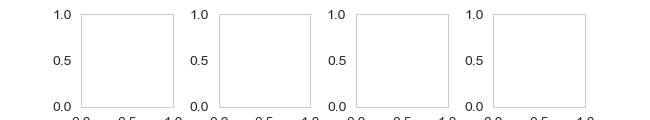

In [3]:
# PLOT VARIANCE VS INERTIA
import scipy.optimize as opt
import math
fig = plt.figure(figsize=(6.5,1.2))
gs = gridspec.GridSpec(1,4,wspace = .5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])
axes = [ax0,ax1,ax2,ax3]

df_list = []
for filename in os.listdir('Experiment_4/Results_4'):
    f = os.path.join('Experiment_4/Results_4', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
df = pd.concat(df_list,ignore_index=True) 
#df = df[df.mse_z<.035]

#df = df[df.n==100]


# Scatter plot

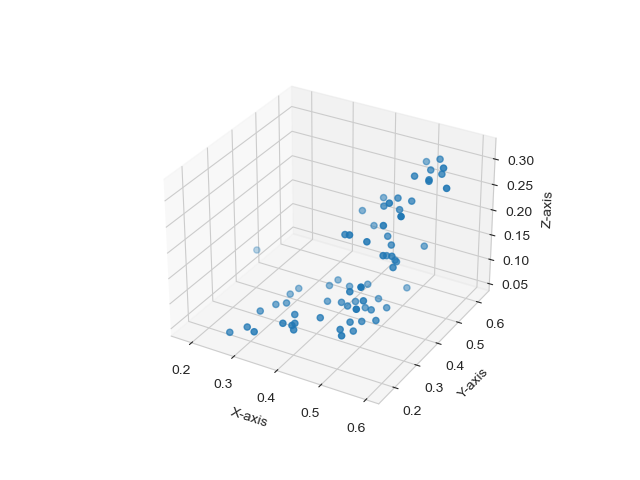

In [19]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Sample data
x = df.kmeans_error.values
y = df.linear_error.values
z = df.pca_error.values

# Create figure and 3D axes
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create the scatter plot
ax.scatter(x, y, z)

# Set labels
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Z-axis')

plt.show()

In [17]:
x.shape

(61,)

Text(0.5, 0.92, 'Interactive 3D Scatter Plot')

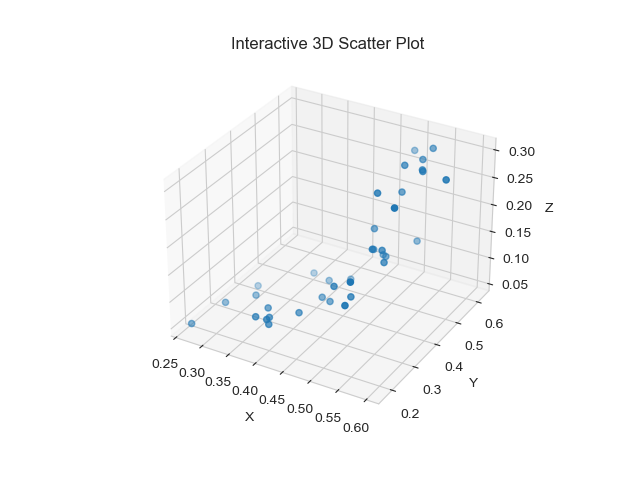

In [12]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Enable interactive plots


# Create a figure and a 3D axes object
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Generate random data for the scatter plot


# Create the scatter plot
ax.scatter3D(x, y, z)

# Set labels and title
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Interactive 3D Scatter Plot')

# Show the plot


In [22]:
x = df[['kmeans_error','linear_error']].values
y = df.pca_error.values

In [46]:
poly = PolynomialFeatures (degree=2, include_bias=True)

In [47]:
poly_features = poly.fit_transform(x)
poly_features = poly_features[:,[0,4]]

In [48]:
poly_reg_model = LinearRegression()

In [49]:
poly_reg_model.fit(poly_features, y)

LinearRegression()

In [43]:
poly.get_feature_names_out()

array(['1', 'x0', 'x1', 'x0^2', 'x0 x1', 'x1^2'], dtype=object)

In [28]:
poly_features.shape

(12750, 5)

In [50]:
poly_reg_model.score(poly_features,y)

0.9738075801330848

In [51]:
poly_reg_model.coef_

array([0.       , 1.3283873])